
# Single-Sérsic fitter validation

This notebook checks the most minimal BayMorph fitting problem:

**Can the fitter recover a noiseless, PSF-free, single-Sérsic galaxy generated by BayMorph itself?**

This is deliberately **not** a pipeline test. It avoids:

- FITS I/O
- image preparation
- background subtraction
- source detection
- segmentation
- empirical noise estimation
- PSF convolution
- injected noise

The only components tested here are:

```text
SersicModel.render -> gaussian likelihood -> DynestyFitter
```


In [1]:

import numpy as np
import matplotlib.pyplot as plt

from baymorph.models import SersicModel
from baymorph.fitting.dynesty_generic import DynestyFitter


In [2]:

# Ground-truth galaxy parameters.
# Important: theta is in radians in BayMorph.

shape = (101, 101)

truth = {
    "flux": 1.0e5,
    "re": 8.0,
    "n": 2.0,
    "q": 0.65,
    "theta": np.deg2rad(30.0),
    "x0": 50.0,
    "y0": 50.0,
}

truth_model = SersicModel(**truth)
data = truth_model.render(shape)

# No noise is injected into the image.
# The noise map only defines the Gaussian likelihood scale.
noise = np.ones(shape)

# In BayMorph, mask=True means excluded pixel.
# Here all pixels are valid, so the mask is all False.
mask = np.zeros(shape, dtype=bool)

print(f"Total flux in rendered image: {data.sum():.6f}")
print(f"Peak pixel value: {data.max():.6f}")


Total flux in rendered image: 100000.000000
Peak pixel value: 5662.415071


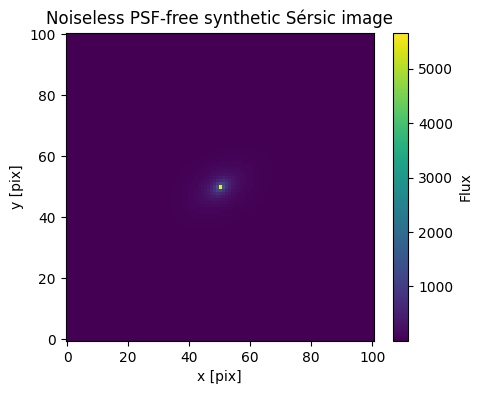

In [3]:

plt.figure(figsize=(5, 4))
plt.imshow(data, origin="lower")
plt.colorbar(label="Flux")
plt.title("Noiseless PSF-free synthetic Sérsic image")
plt.xlabel("x [pix]")
plt.ylabel("y [pix]")
plt.show()


In [4]:

def make_model(flux, re, n, q, theta, x0, y0):
    return SersicModel(
        flux=flux,
        re=re,
        n=n,
        q=q,
        theta=theta,
        x0=x0,
        y0=y0,
    )

parameter_names = [
    "flux",
    "re",
    "n",
    "q",
    "theta",
    "x0",
    "y0",
]

# Moderately informative priors around the known synthetic setup.
# These are still broad enough to test recovery, but not so broad that the
# exact no-noise likelihood becomes inefficient for nested sampling.
prior_bounds = {
    "flux": (0.5e5, 1.5e5),
    "re": (4.0, 12.0),
    "n": (0.8, 4.0),
    "q": (0.35, 0.95),
    "theta": (-0.5 * np.pi, 0.5 * np.pi),
    "x0": (48.0, 52.0),
    "y0": (48.0, 52.0),
}

fitter = DynestyFitter(
    model_factory=make_model,
    data=data,
    noise=noise,
    parameter_names=parameter_names,
    prior_bounds=prior_bounds,
    mask=mask,
)


In [5]:

result = fitter.run(
    nlive=100,
    sample="rwalk",
    bound="multi",
    dlogz=0.01,
    seed=42,
    print_progress=True,
)


iter: 11479 | +100 | bound: 142 | nc: 1 | ncall: 304640 | eff(%):  3.802 | loglstar:   -inf < -9374.640 <    inf | logz: -9484.248 +/-  1.022 | dlogz:  0.000 >  0.010                                


## Parameter recovery

For a clean visual diagnostic, we summarize the raw Dynesty samples using percentiles.

This is sufficient for this notebook-level validation. For publication-level posterior summaries, we may later add explicit equal-weight posterior resampling from the Dynesty weights.


In [6]:

samples = result.samples

summary = {}
for i, name in enumerate(result.parameter_names):
    p16, p50, p84 = np.percentile(samples[:, i], [16, 50, 84])
    summary[name] = (p16, p50, p84)

print("Parameter recovery")
print("------------------")

for name in result.parameter_names:
    p16, p50, p84 = summary[name]
    true_value = truth[name]

    if name == "theta":
        true_display = np.rad2deg(true_value)
        p16_display = np.rad2deg(p16)
        p50_display = np.rad2deg(p50)
        p84_display = np.rad2deg(p84)
        unit = "deg"
    else:
        true_display = true_value
        p16_display = p16
        p50_display = p50
        p84_display = p84
        unit = ""

    print(
        f"{name:>6s}: true={true_display: .6g} {unit:>3s} | "
        f"p50={p50_display: .6g} | "
        f"-={p50_display - p16_display: .3g} "
        f"+={p84_display - p50_display: .3g}"
    )


Parameter recovery
------------------
  flux: true= 100000     | p50= 100464 | -= 375 += 1.99e+03
    re: true= 8     | p50= 8.06245 | -= 0.0472 += 0.346
     n: true= 2     | p50= 2.02579 | -= 0.016 += 0.241
     q: true= 0.65     | p50= 0.650304 | -= 0.00107 += 0.00791
 theta: true= 30 deg | p50= 30.0205 | -= 0.121 += 0.307
    x0: true= 50     | p50= 50.0002 | -= 0.00178 += 0.002
    y0: true= 50     | p50= 50 | -= 0.00118 += 0.00179


In [7]:

# Build the median model.

best = {
    name: np.percentile(samples[:, i], 50)
    for i, name in enumerate(result.parameter_names)
}

best_model = SersicModel(**best)
model_image = best_model.render(shape)
residual = data - model_image

print(f"Data flux:       {data.sum():.8f}")
print(f"Model flux:      {model_image.sum():.8f}")
print(f"Relative error:  {(model_image.sum() - data.sum()) / data.sum():.3e}")
print(f"Max |residual|:  {np.max(np.abs(residual)):.6e}")
print(f"RMS residual:    {np.sqrt(np.mean(residual**2)):.6e}")


Data flux:       100000.00000000
Model flux:      100463.66322928
Relative error:  4.637e-03
Max |residual|:  8.775146e+01
RMS residual:    8.805263e-01


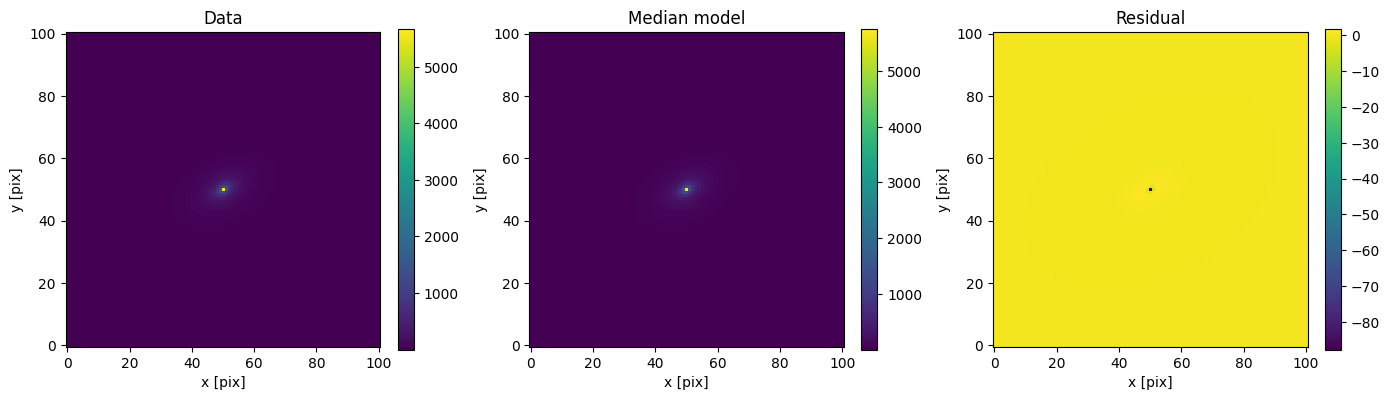

In [8]:

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

im0 = axes[0].imshow(data, origin="lower")
axes[0].set_title("Data")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(model_image, origin="lower")
axes[1].set_title("Median model")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

im2 = axes[2].imshow(residual, origin="lower")
axes[2].set_title("Residual")
plt.colorbar(im2, ax=axes[2], fraction=0.046)

for ax in axes:
    ax.set_xlabel("x [pix]")
    ax.set_ylabel("y [pix]")

plt.tight_layout()
plt.show()


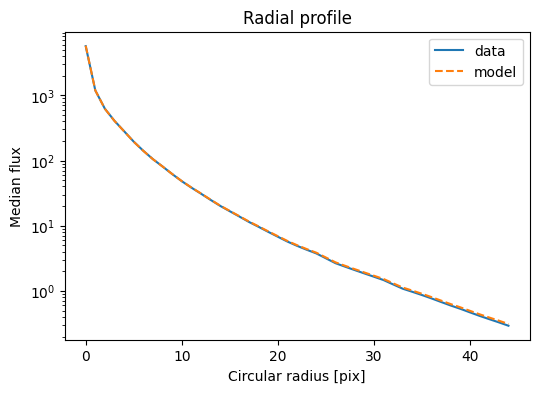

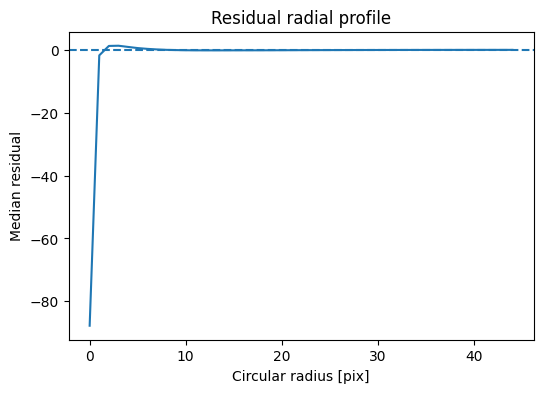

In [9]:

# Circular radial profile diagnostic.
# This is intentionally simple and independent of the fitted ellipticity.

yy, xx = np.indices(shape)
rr = np.sqrt((xx - truth["x0"])**2 + (yy - truth["y0"])**2)
r_int = rr.astype(int)

radii = np.arange(0, 45)
data_prof = []
model_prof = []
resid_prof = []

for radius in radii:
    annulus = r_int == radius
    data_prof.append(np.nanmedian(data[annulus]))
    model_prof.append(np.nanmedian(model_image[annulus]))
    resid_prof.append(np.nanmedian(residual[annulus]))

plt.figure(figsize=(6, 4))
plt.semilogy(radii, data_prof, label="data")
plt.semilogy(radii, model_prof, "--", label="model")
plt.xlabel("Circular radius [pix]")
plt.ylabel("Median flux")
plt.title("Radial profile")
plt.legend()
plt.show()

plt.figure(figsize=(6, 4))
plt.axhline(0.0, linestyle="--")
plt.plot(radii, resid_prof)
plt.xlabel("Circular radius [pix]")
plt.ylabel("Median residual")
plt.title("Residual radial profile")
plt.show()



## Interpretation

If this notebook recovers the input parameters, then the following core components are behaving consistently in this idealized case:

- `SersicModel.render`
- `gaussian_log_likelihood`
- `DynestyFitter`
- the parameter convention for `flux`, `re`, `n`, `q`, `theta`, `x0`, and `y0`

If this works but a full synthetic pipeline test does not, the discrepancy should be investigated in the additional pipeline ingredients: FITS handling, background subtraction, noise-map construction, masking, segmentation, or PSF treatment.
